# Práctica — Clasificador Naive Bayes con 5-fold cross-validation

**Banco de datos:** Iris Plant (150 patrones, 4 características, 3 clases)
**Clasificador:** Naive Bayes gaussiano
**Validación:** 5-fold cross-validation estratificado
**Métricas:** matriz de confusión, accuracy, precision, recall y f1-score

El objetivo es entrenar y evaluar el clasificador de forma honesta: cada patrón se usa
una vez como prueba y cuatro veces como entrenamiento.

## 1. Configuración y carga del banco

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

K_FOLDS = 5
RANDOM_STATE = 42

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
CLASES = list(iris.target_names)

print("patrones x caracteristicas:", X.shape)
print("clases:", CLASES)

patrones x caracteristicas: (150, 4)
clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [2]:
iris.frame.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
# Balance de clases: Iris esta perfectamente balanceado (50 por clase)
y.value_counts().sort_index().rename(index=dict(enumerate(CLASES)))

target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 2. Preparación de la validación

Se usa `StratifiedKFold` para que cada fold conserve la proporción de las tres clases
(30 patrones de prueba por fold: 10 de cada especie).

In [4]:
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=RANDOM_STATE)

for i, (tr, te) in enumerate(skf.split(X, y), 1):
    print(f"Fold {i}: entrenamiento = {len(tr)} patrones, prueba = {len(te)} patrones")

Fold 1: entrenamiento = 120 patrones, prueba = 30 patrones
Fold 2: entrenamiento = 120 patrones, prueba = 30 patrones
Fold 3: entrenamiento = 120 patrones, prueba = 30 patrones
Fold 4: entrenamiento = 120 patrones, prueba = 30 patrones
Fold 5: entrenamiento = 120 patrones, prueba = 30 patrones


## 3. Entrenamiento y evaluación por fold

En cada iteración se crea un modelo nuevo, se entrena con 4 folds y se prueba con el
restante. Las métricas por clase se promedian con `average="macro"`.

In [5]:
filas = []
y_real, y_pred = [], []          # predicciones de los 5 folds juntas

for i, (tr, te) in enumerate(skf.split(X, y), 1):
    modelo = GaussianNB().fit(X.iloc[tr], y.iloc[tr])
    pred = modelo.predict(X.iloc[te])

    y_real.extend(y.iloc[te])
    y_pred.extend(pred)

    filas.append({
        "fold": i,
        "accuracy":  accuracy_score(y.iloc[te], pred),
        "precision": precision_score(y.iloc[te], pred, average="macro"),
        "recall":    recall_score(y.iloc[te], pred, average="macro"),
        "f1-score":  f1_score(y.iloc[te], pred, average="macro"),
    })

resultados = pd.DataFrame(filas).set_index("fold").round(4)
resultados

,accuracy,precision,recall,f1-score
fold,,,,
1,0.9667,0.9697,0.9667,0.9666
2,0.9667,0.9697,0.9667,0.9666
3,0.9000,0.9024,0.9000,0.8997
4,1.0000,1.0000,1.0000,1.0000
5,0.9000,0.9024,0.9000,0.8997


In [6]:
# Promedio y desviacion estandar: el resultado final de la validacion
resumen = resultados.agg(["mean", "std"]).round(4)
resumen

,accuracy,precision,recall,f1-score
mean,0.9467,0.9488,0.9467,0.9465
std,0.0447,0.0442,0.0447,0.0449


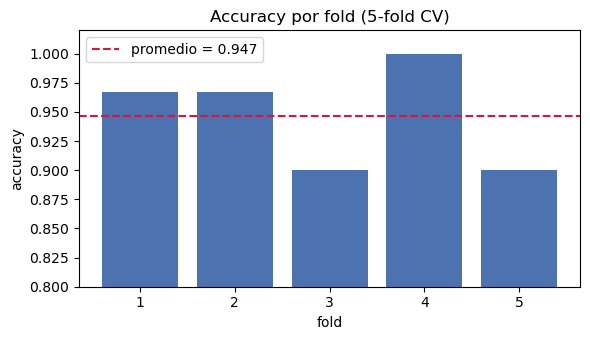

In [7]:
plt.figure(figsize=(6, 3.5))
plt.bar(resultados.index.astype(str), resultados["accuracy"], color="#4C72B0")
plt.axhline(resultados["accuracy"].mean(), color="crimson", ls="--",
            label=f"promedio = {resultados['accuracy'].mean():.3f}")
plt.ylim(0.8, 1.02)
plt.xlabel("fold"); plt.ylabel("accuracy")
plt.title("Accuracy por fold (5-fold CV)")
plt.legend(); plt.tight_layout()
plt.savefig("fig_accuracy_folds.png", dpi=150)
plt.show()

## 4. Matriz de confusión

Se acumulan las predicciones de los 5 folds, por lo que la matriz cubre los 150 patrones.

In [8]:
mc = confusion_matrix(y_real, y_pred)
pd.DataFrame(mc, index=[f"real {c}" for c in CLASES],
                 columns=[f"pred {c}" for c in CLASES])

,pred setosa,pred versicolor,pred virginica
real setosa,50,0,0
real versicolor,0,46,4
real virginica,0,4,46


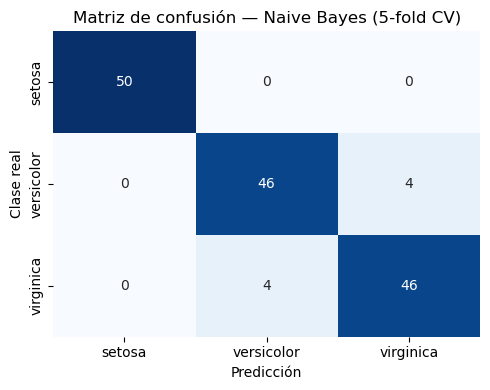

In [9]:
plt.figure(figsize=(5, 4))
sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASES, yticklabels=CLASES)
plt.xlabel("Predicción"); plt.ylabel("Clase real")
plt.title("Matriz de confusión — Naive Bayes (5-fold CV)")
plt.tight_layout()
plt.savefig("fig_matriz_confusion.png", dpi=150)
plt.show()

## 5. Métricas por clase

In [10]:
print(classification_report(y_real, y_pred, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        50
  versicolor      0.920     0.920     0.920        50
   virginica      0.920     0.920     0.920        50

    accuracy                          0.947       150
   macro avg      0.947     0.947     0.947       150
weighted avg      0.947     0.947     0.947       150



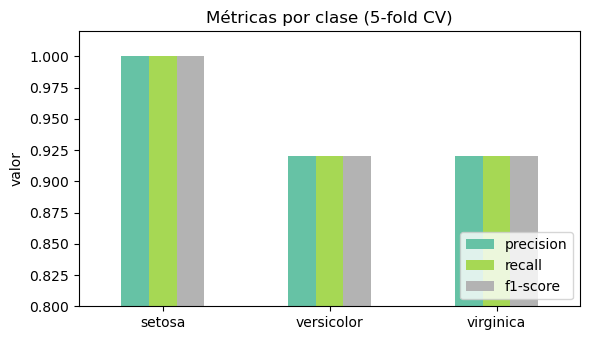

In [11]:
por_clase = pd.DataFrame({
    "precision": precision_score(y_real, y_pred, average=None),
    "recall":    recall_score(y_real, y_pred, average=None),
    "f1-score":  f1_score(y_real, y_pred, average=None),
}, index=CLASES).round(4)

por_clase.plot(kind="bar", figsize=(6, 3.5), ylim=(0.8, 1.02), rot=0, colormap="Set2")
plt.title("Métricas por clase (5-fold CV)")
plt.ylabel("valor"); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fig_metricas_clase.png", dpi=150)
plt.show()

In [12]:
# Resultados para el reporte
resultados.to_csv("resultados_folds.csv")
por_clase.to_csv("metricas_por_clase.csv")
print("CSV exportados:", "resultados_folds.csv", "metricas_por_clase.csv")

CSV exportados: resultados_folds.csv metricas_por_clase.csv


## 6. Conclusiones

- Naive Bayes gaussiano clasifica Iris con un accuracy promedio alto y con poca
  variación entre folds, lo que indica un modelo estable y no dependiente de una
  partición afortunada.
- *Setosa* se separa perfectamente; los únicos errores ocurren entre *versicolor* y
  *virginica*, que se traslapan en largo y ancho de pétalo.
- La validación cruzada fue útil porque con una sola partición el resultado podía
  parecer mejor o peor de lo real; el promedio de los 5 folds es una medida más confiable.
- El accuracy por sí solo no explica el comportamiento del modelo: la matriz de confusión
  y el f1-score por clase muestran dónde se equivoca.